# Endterm 05 - Start-stop and detailed transmission

## Summary

The controlled three-variant study reduced ANN validation MAE from **1.082715 to 0.805409 MPG** (25.61%). With both features ANN has RMSE **1.197025 MPG**, R-squared **0.962684** and the lowest validation MAE among the six compared models. Classical training-only CV errors also decreased. These are repeated-validation development results, not independent test confirmation.

This notebook reads frozen artifacts and verifies saved predictions. It does not train, download data, evaluate test or overwrite the original endterm experiment. See `project.ipynb` for the integrated report and `docs/feature_extension_results_ru.md` for defense notes.

## Context and methods

### Key assumptions

Use the existing real EPA snapshot and fixed seed-42 duplicate-grouped split. Attach `startStop` and `trany` after splitting by immutable raw row ID. Retain original duplicate-group definitions and all train/validation rows. `start_stop` maps Y/N to 1/0; unknown values remain missing. `transmission_detail` is a categorical replacement for coarse Automatic/Manual/Other. Its one-hot vocabulary, imputation and scaling are fitted only on train.

Compare original; +start-stop; +start-stop and detailed transmission. There is no transmission-only arm, so the study does not isolate its standalone effect or feature interaction. Classical parameters are frozen at the prior selected settings; GroupKFold(5) is within train. ANN uses the original selected 64/32 architecture and lr=0.001, one seed-42 run per arm, Adam/MSE, batch 64, cap 200, patience 20 and best-validation-MSE checkpoints. There is no new grid or ANN CV.

The original holdout has already been used; do not tune against it or attach old test scores to the new models. Protocol: `docs/feature_extension_protocol.json`; implementation: `src/vehicle_efficiency/feature_extension.py`.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from vehicle_efficiency.feature_extension import (
    RESULTS, FIGURES, VARIANTS, input_columns, load_extension_data,
    variant_manifest, verify,
)
from vehicle_efficiency.neural_network import load_ann

table = pd.read_csv(RESULTS / 'ablation_validation.csv')
full = pd.read_csv(RESULTS / 'model_comparison_validation.csv')
display(verify())

{'variants': 3,
 'models_per_variant': 6,
 'validation_rows': 2080,
 'predictions_and_metrics': 'match',
 'original_artifacts': 'unchanged',
 'test_evaluated': False}

## Data

Only 9,816 training rows and 2,080 validation rows are exposed to the experiment. The source and split hashes are unchanged. The added fields have no missing values on train; transmission has 33 detailed categories versus two coarse categories. ANN input dimensions become 40, 41 and 72 after preprocessing.

In [2]:
train, validation, original_manifest = load_extension_data()
display(train[['model_year', 'transmission', 'transmission_detail', 'start_stop']].head(8))
display(train[['start_stop', 'transmission_detail']].isna().sum().to_frame('Missing on train'))
display(train.start_stop.value_counts().rename_axis('Start-stop flag').to_frame('Training rows'))
print('Training detailed transmission categories:', train.transmission_detail.nunique())

,model_year,transmission,transmission_detail,start_stop
1,2015,Automatic,Automatic (S6),0.0
2,2015,Automatic,Automatic (S6),0.0
4,2015,Manual,Manual 6-spd,0.0
5,2015,Automatic,Automatic 8-spd,0.0
6,2015,Automatic,Automatic 8-spd,0.0
7,2015,Automatic,Automatic 6-spd,0.0
9,2015,Manual,Manual 6-spd,0.0
11,2015,Automatic,Automatic 6-spd,0.0


,Missing on train
start_stop,0
transmission_detail,0


,Training rows
Start-stop flag,
1.0,5419
0.0,4397


Training detailed transmission categories: 33


## Results - feature ablation

MAE is in US MPG and lower is better. Each column uses the same validation row IDs and y_true; compare against the rerun original in the same environment, rather than mixing historical platform results.

Validation MAE (US MPG)


variant,original,start_stop,start_stop_transmission
model,,,
Baseline (mean),4.661760,4.661760,4.661760
Decision Tree,1.051024,0.997551,0.836948
Feedforward ANN,1.082715,1.010398,0.805409
KNN,1.092308,1.035577,0.834135
Linear Regression,2.018650,1.993378,1.749138
Ridge,2.020510,1.995525,1.750653


Training-only grouped 5-fold CV MAE (US MPG)


variant,original,start_stop,start_stop_transmission
model,,,
Baseline (mean),4.635465,4.635465,4.635465
Decision Tree,1.089671,1.026267,0.842327
KNN,1.113729,1.058173,0.875070
Linear Regression,1.985638,1.950735,1.717523
Ridge,1.985560,1.950895,1.719178


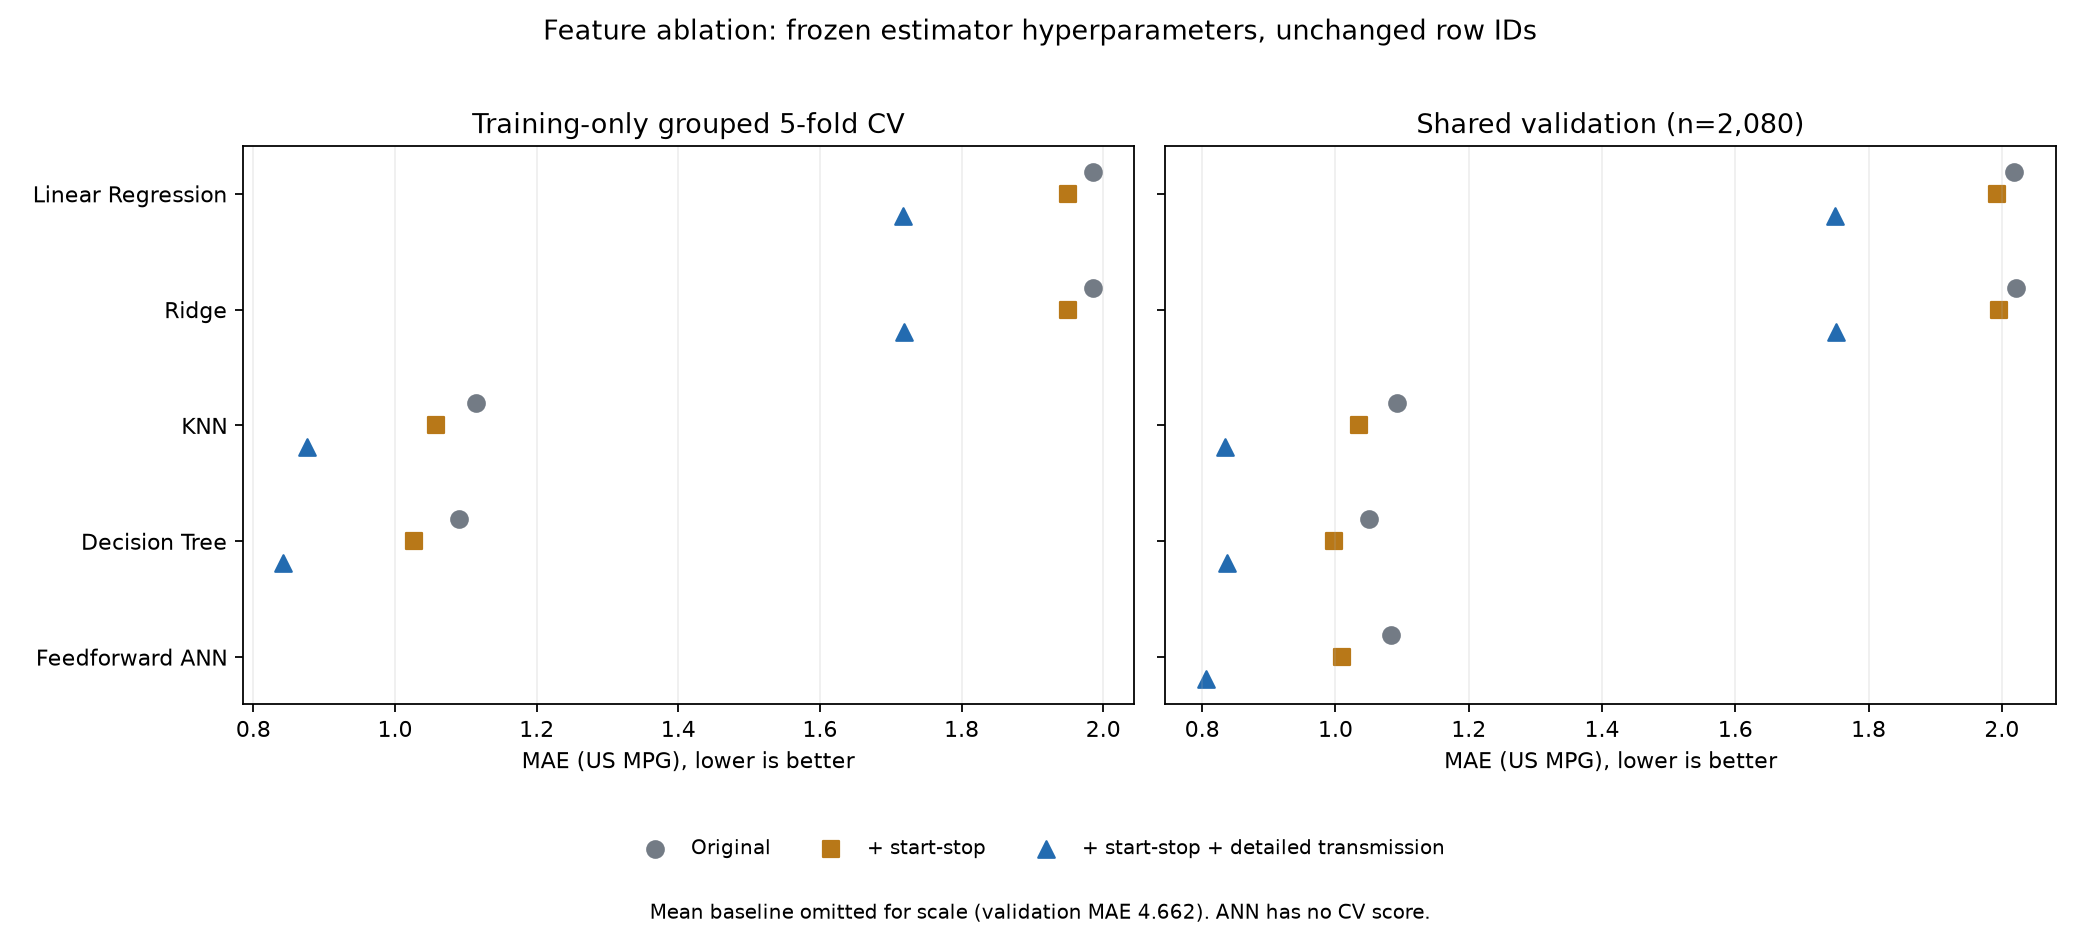

In [3]:
validation_mae = table.pivot(index='model', columns='variant', values='validation_mae').reindex(columns=VARIANTS)
print('Validation MAE (US MPG)')
display(validation_mae.round(6))
cv_mae = table[table.model != 'Feedforward ANN'].pivot(index='model', columns='variant', values='cv_mae').reindex(columns=VARIANTS)
print('Training-only grouped 5-fold CV MAE (US MPG)')
display(cv_mae.round(6))
display(Image(filename=str(FIGURES / 'feature_ablation.png')))

The mean baseline is unchanged. Adding start-stop improves all tested non-dummy models, and the combined representation improves them further. The tree's grouped-CV MAE falls from 1.090 to 0.842 and validation MAE from 1.051 to 0.837. ANN validation MAE falls from 1.083 to 0.805. These results support keeping the extended representation for this branch; they do not establish statistical or causal effects.

### Six-model comparison with both features

In [4]:
display(full[['model', 'train_mae', 'validation_mae', 'validation_rmse', 'validation_r2']].round(6))

,model,train_mae,validation_mae,validation_rmse,validation_r2
0,Feedforward ANN,0.655774,0.805409,1.197025,0.962684
1,KNN,0.547270,0.834135,1.380012,0.950404
2,Decision Tree,0.455725,0.836948,1.417257,0.947690
3,Linear Regression,1.705767,1.749138,2.388365,0.851446
4,Ridge,1.707360,1.750653,2.388000,0.851491
5,Baseline (mean),4.634994,4.661760,6.196671,-0.000000


ANN leads the declared validation-MAE metric. KNN (0.834) and tree (0.837) are close; their order is not a robust superiority claim. Frozen original hyperparameters make the feature comparison controlled, but may not be optimal for the new representation.

### ANN convergence and overfitting

,variant,input_dim,best_epoch,epochs_run,train_mae,validation_mae
5,original,40.0,113.0,133.0,0.946014,1.082715
11,start_stop,41.0,198.0,200.0,0.831200,1.010398
17,start_stop_transmission,72.0,134.0,154.0,0.655774,0.805409


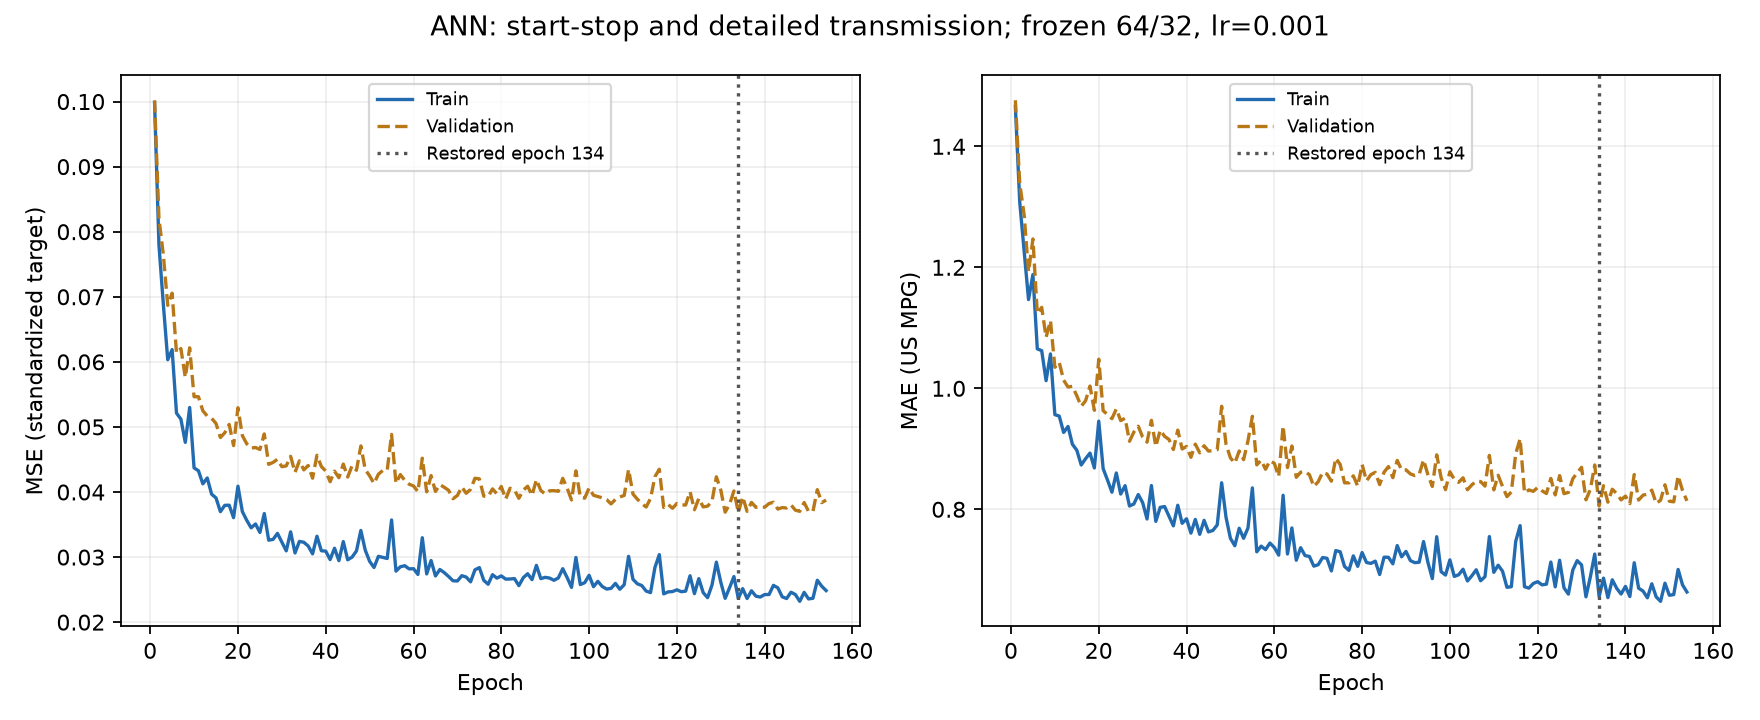

In [5]:
display(table[table.model == 'Feedforward ANN'][['variant', 'input_dim', 'best_epoch', 'epochs_run', 'train_mae', 'validation_mae']].round(6))
display(Image(filename=str(FIGURES / 'ann_learning_curves.png')))

The combined model restores epoch 134 and stops at 154. Its train MAE is 0.656 versus validation 0.805, leaving a generalization gap of about 0.150 MPG. The start-stop-only run reaches the 200-epoch cap (best 198), so training budget limits that arm. No additional trials or longer runs were added after reviewing outcomes. Changed input dimensions also change initialized network weights; this is a one-seed predictive ablation, not a strict causal intervention.

### Validation error analysis

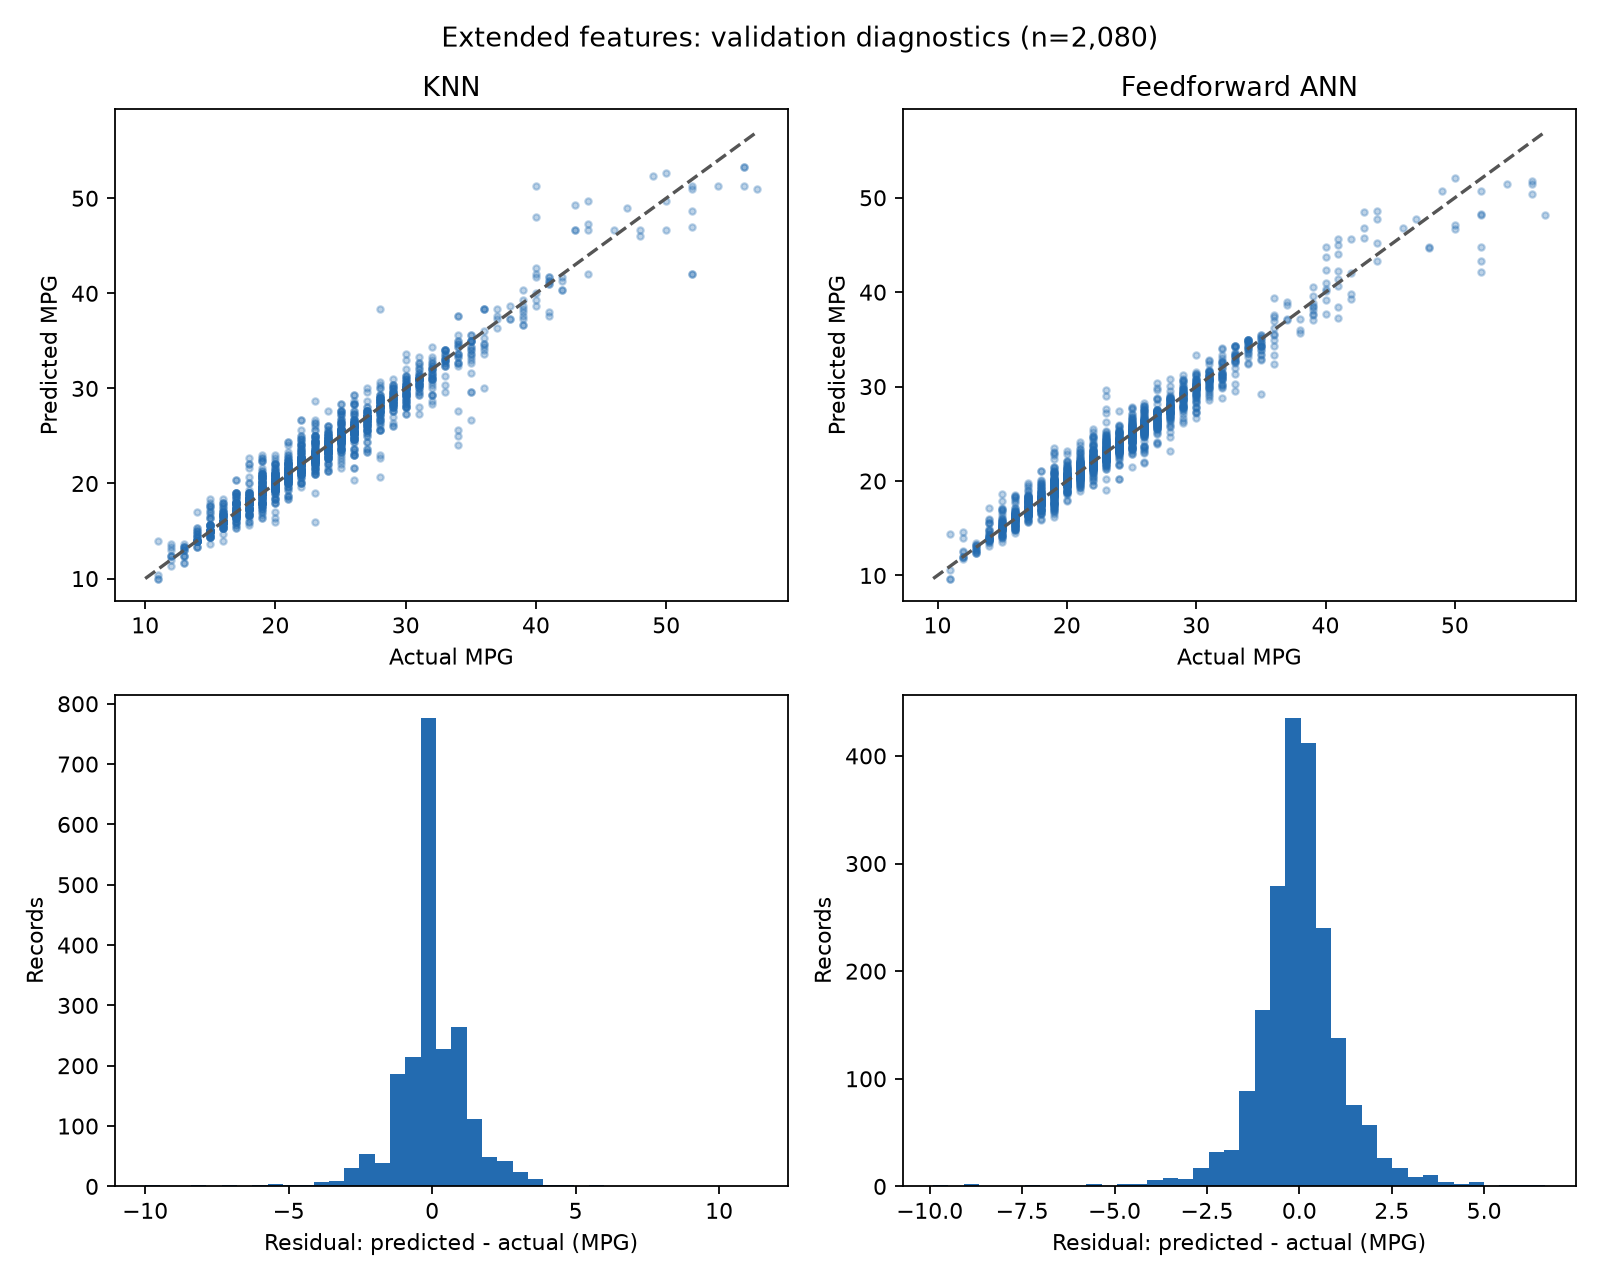

,group,n,mae,mean_error,model,group_type
0,0,1839,0.7428,-0.0283,KNN,hybrid
1,1,241,1.5311,0.1535,KNN,hybrid
24,0.0,923,0.6948,-0.0592,KNN,start_stop
25,1.0,1157,0.9453,0.0343,KNN,start_stop
55,0,1839,0.7247,0.0358,Feedforward ANN,hybrid
56,1,241,1.4215,-0.2297,Feedforward ANN,hybrid
79,0.0,923,0.6879,-0.0163,Feedforward ANN,start_stop
80,1.0,1157,0.8991,0.0220,Feedforward ANN,start_stop


,model_predictor,make,model_vehicle,y_true,y_pred,absolute_error
0,KNN,Honda,CR-V FWD,40,51.333,11.333
1,KNN,Mitsubishi,Outlander 2WD,28,38.333,10.333
2,KNN,BMW,328d xDrive,34,24.000,10.000
10,Feedforward ANN,Toyota,Camry Hybrid LE,52,42.094,9.906
11,Feedforward ANN,Toyota,Prius,57,48.133,8.867
12,Feedforward ANN,Toyota,Camry Hybrid LE,52,43.298,8.702


In [6]:
display(Image(filename=str(FIGURES / 'evaluation_validation.png')))
errors = pd.read_csv(RESULTS / 'error_by_group_validation.csv')
display(errors[errors.group_type.isin(['hybrid', 'start_stop'])].round(4))
largest = pd.read_csv(RESULTS / 'largest_errors_validation.csv')
display(largest.groupby('model_predictor', sort=False).head(3)[
    ['model_predictor', 'make', 'model_vehicle', 'y_true', 'y_pred', 'absolute_error']].round(3))

Residuals are predicted minus actual MPG. Group errors must be read with sample counts; technology groups differ in other properties, so their MAE differences do not prove a causal start-stop effect. Full per-transmission and per-class tables are saved with the experiment.

### Historical reconciliation

The original ANN control reproduces saved predictions within 1e-10. The historical KNN score differs slightly because predictions at equal-distance neighbor cutoffs differ: every one of the 292 changed rows has equal third/fourth distances. The rerun original is the comparison baseline for all new arms. Ridge's historical metric difference is approximately 0.0000022 MPG.

In [7]:
display(json.loads((RESULTS / 'knn_historical_ties.json').read_text()))

{'changed_prediction_rows': 292,
 'all_changed_rows_have_equal_third_fourth_distance': True,
 'total_boundary_tie_rows': 1329,
 'interpretation': 'Equal-distance neighbor selection differs; compare variants against the rerun current-environment control'}

### Load the extended model without retraining

In [8]:
variant = VARIANTS[-1]
model = load_ann(RESULTS / f'ann_{variant}', expected_manifest=variant_manifest(original_manifest, variant))
example = validation.iloc[:1]
display(example[['make', 'model', 'model_year', 'transmission_detail', 'start_stop', 'mpg']])
print(f'Frozen ANN prediction: {model.predict(example)[0]:.6f} MPG')
print('Raw predictors:', input_columns(variant))

,make,model,model_year,transmission_detail,start_stop,mpg
3,Mazda,6,2015,Automatic (S6),0.0,32


Frozen ANN prediction: 28.755892 MPG
Raw predictors: ['model_year', 'cylinders', 'displacement', 'hybrid', 'turbo', 'supercharged', 'drive', 'transmission_detail', 'vehicle_class', 'fuel_type', 'start_stop']


## Takeaways and limitations

Keep the two-feature extension for the branch's updated validation results; retain the original experiment for provenance. No new test score is available for the new models. Validation was reused for previous choices, early stopping and comparison, so results are selection-biased. One seed, fixed original hyperparameters, related variants across splits, absent weight/horsepower and EPA laboratory ratings limit generalization.

K-Means/PCA remain the existing engine analysis on the identical training rows. The source, topic, team and scope have not changed. Use the observed ablation as evidence of justified feature engineering, with the final six-model table, learning curves and error analysis. Re-run `python -m vehicle_efficiency.feature_extension --verify` to check all 18 saved prediction groups and parent-artifact preservation. Only the explicit module training command starts a new experiment; it refuses to overwrite a completed one.